<a href="https://colab.research.google.com/github/2410010585amel/statistika-probabilitas-uniska/blob/main/M10_Praktikum_Inferensial_Tips_FadliatulAmaliyah.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🧪 Modul 10 — Praktikum Statistika Inferensial

### Studi Kasus: Restaurant Tips — Confidence Interval, t-test, Chi-Square, ANOVA + Template Milestone 2

**Mata Kuliah:** Statistika & Probabilitas (TIF1501)
**Program Studi:** Teknik Informatika (55201) · FTI · Uniska MAB Banjarmasin
**Semester:** 5 · 3 SKS · CPMK072 (Sub-CPMK 072.2)

---

## 🎯 Tujuan Pembelajaran

1. **Menghitung & menafsirkan** Confidence Interval 95% untuk mean.
2. **Menerapkan** kerangka uji hipotesis 5 langkah (H₀/H₁, α, uji, p-value, keputusan).
3. **Memilih & menjalankan** t-test, chi-square, dan ANOVA sesuai tipe data.
4. **Menyusun** Milestone 2: uji 2-3 hipotesis pada dataset Kaggle pilihan sendiri.

---

## 📋 Alur Notebook

| Bagian | Isi | Waktu |
|--------|-----|-------|
| **A** | Setup & Load Tips | 5 menit |
| **B** | EDA Singkat (recap M9) | 10 menit |
| **C** | Confidence Interval + Simulasi 100 CI | 15 menit |
| **D** | t-test (one-sample & two-sample) + effect size | 15 menit |
| **E** | Chi-Square Test of Independence | 10 menit |
| **F** | One-way ANOVA + Post-hoc Tukey | 15 menit |
| **G** | Korelasi & Tabel Ringkasan | 10 menit |
| **H** | Template Milestone 2 + Refleksi | 10 menit |

**Total: ± 90 menit**

---

## 💡 Kenapa Dataset Tips?

- ✅ **244 transaksi restoran** nyata dengan 7 kolom (numerik + kategorik)
- ✅ Cocok untuk **semua jenis uji**: numerik vs grup (t-test, ANOVA), kategorik vs kategorik (chi-square)
- ✅ Hasilnya **campuran signifikan & tidak signifikan** — melatih Anda membaca p-value dengan jujur
- ✅ Konteks bisnis jelas: strategi staffing restoran, kebijakan service charge


---

# 🔧 A. Setup & Load Dataset


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
np.random.seed(42)

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/tips.csv"
df = pd.read_csv(url)

# Fitur turunan: persentase tip terhadap tagihan
df['tip_pct'] = df['tip'] / df['total_bill'] * 100

ALPHA = 0.05
print(f"Shape: {df.shape[0]} transaksi × {df.shape[1]} kolom")
df.head()


Shape: 244 transaksi × 8 kolom


,total_bill,tip,sex,smoker,day,time,size,tip_pct
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


---

# 🔍 B. EDA Singkat (Recap Modul 9)

Sebelum menguji hipotesis, selalu lihat datanya dulu. Grafik memberi **dugaan**; uji statistik memberi **bukti**.


In [ ]:
print(df[['total_bill', 'tip', 'tip_pct', 'size']].describe().round(2))
print("\nKolom kategorik:")
for col in ['sex', 'smoker', 'day', 'time']:
    print(f"  {col:<7}: {df[col].value_counts().to_dict()}")


       total_bill     tip  tip_pct    size
count      244.00  244.00   244.00  244.00
mean        19.79    3.00    16.08    2.57
std          8.90    1.38     6.11    0.95
min          3.07    1.00     3.56    1.00
25%         13.35    2.00    12.91    2.00
50%         17.80    2.90    15.48    2.00
75%         24.13    3.56    19.15    3.00
max         50.81   10.00    71.03    6.00

Kolom kategorik:
  sex    : {'Male': 157, 'Female': 87}
  smoker : {'No': 151, 'Yes': 93}
  day    : {'Sat': 87, 'Sun': 76, 'Thur': 62, 'Fri': 19}
  time   : {'Dinner': 176, 'Lunch': 68}


/tmp/ipykernel_2643/333812482.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='sex', y='tip', data=df, ax=axes[0], palette=['#059669', '#7C3AED'])
/tmp/ipykernel_2643/333812482.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='day', y='total_bill', data=df, ax=axes[1], order=['Thur', 'Fri', 'Sat', 'Sun'], palette='Set2')


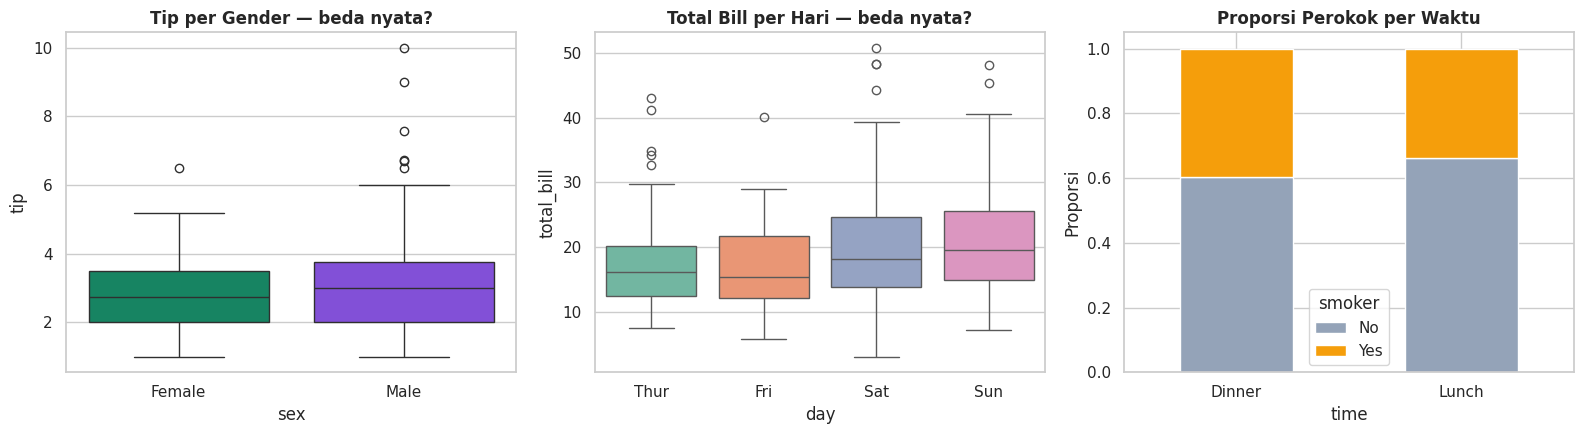

💡 Dari grafik: pria tampak memberi tip sedikit lebih besar, weekend tampak lebih mahal.
   Tapi apakah perbedaannya NYATA atau hanya kebetulan sampling? → Uji hipotesis!


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
sns.boxplot(x='sex', y='tip', data=df, ax=axes[0], palette=['#059669', '#7C3AED'])
axes[0].set_title('Tip per Gender — beda nyata?', fontweight='bold')
sns.boxplot(x='day', y='total_bill', data=df, ax=axes[1], order=['Thur', 'Fri', 'Sat', 'Sun'], palette='Set2')
axes[1].set_title('Total Bill per Hari — beda nyata?', fontweight='bold')
pd.crosstab(df['smoker'], df['time'], normalize='columns').T.plot(kind='bar', stacked=True, ax=axes[2], color=['#94A3B8', '#F59E0B'])
axes[2].set_title('Proporsi Perokok per Waktu', fontweight='bold')
axes[2].set_ylabel('Proporsi'); axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

print("💡 Dari grafik: pria tampak memberi tip sedikit lebih besar, weekend tampak lebih mahal.")
print("   Tapi apakah perbedaannya NYATA atau hanya kebetulan sampling? → Uji hipotesis!")


---

# 📏 C. Confidence Interval

**Tujuan Pembelajaran 1** — Mengestimasi rata-rata tip populasi.

$$CI = \bar{x} \pm t_{\alpha/2,\, n-1} \cdot \frac{s}{\sqrt{n}}$$

## C.1 CI 95% Manual vs scipy


In [ ]:
x = df['tip']
n, xbar, s = len(x), x.mean(), x.std(ddof=1)
se = s / np.sqrt(n)
t_crit = stats.t.ppf(1 - ALPHA/2, df=n-1)
margin = t_crit * se

print("=== CI 95% RATA-RATA TIP (MANUAL) ===")
print(f"  n          = {n}")
print(f"  x̄          = ${xbar:.3f}")
print(f"  s          = ${s:.3f}")
print(f"  SE = s/√n  = {se:.4f}")
print(f"  t kritis   = {t_crit:.4f}  (df = {n-1})")
print(f"  margin     = {margin:.4f}")
print(f"  CI 95%     = [${xbar-margin:.3f}, ${xbar+margin:.3f}]")

ci_scipy = stats.t.interval(0.95, df=n-1, loc=xbar, scale=se)
print(f"\nVerifikasi scipy: [${ci_scipy[0]:.3f}, ${ci_scipy[1]:.3f}] ✅")


=== CI 95% RATA-RATA TIP (MANUAL) ===
  n          = 244
  x̄          = $2.998
  s          = $1.384
  SE = s/√n  = 0.0886
  t kritis   = 1.9698  (df = 243)
  margin     = 0.1745
  CI 95%     = [$2.824, $3.173]

Verifikasi scipy: [$2.824, $3.173] ✅


In [ ]:
# Pengaruh tingkat kepercayaan terhadap lebar CI
print(f"{'Level':>7} | {'t kritis':>8} | {'CI':>22} | {'Lebar':>6}")
print("-" * 54)
for conf in [0.80, 0.90, 0.95, 0.99]:
    lo, hi = stats.t.interval(conf, df=n-1, loc=xbar, scale=se)
    print(f"{conf*100:>6.0f}% | {stats.t.ppf((1+conf)/2, n-1):>8.3f} | [${lo:.3f}, ${hi:.3f}]   | {hi-lo:.3f}")
print("\n💡 Makin tinggi tingkat kepercayaan → makin LEBAR interval (trade-off presisi vs keyakinan).")


  Level | t kritis |                     CI |  Lebar
------------------------------------------------------
    80% |    1.285 | [$2.884, $3.112]   | 0.228
    90% |    1.651 | [$2.852, $3.145]   | 0.293
    95% |    1.970 | [$2.824, $3.173]   | 0.349
    99% |    2.596 | [$2.768, $3.228]   | 0.460

💡 Makin tinggi tingkat kepercayaan → makin LEBAR interval (trade-off presisi vs keyakinan).


## C.2 Simulasi: Apa Arti "95%" Sebenarnya?

Kita anggap 244 transaksi sebagai **populasi** (μ diketahui). Ambil 100 sampel acak berukuran 30, hitung CI 95% untuk masing-masing, lalu hitung berapa interval yang mengandung μ.


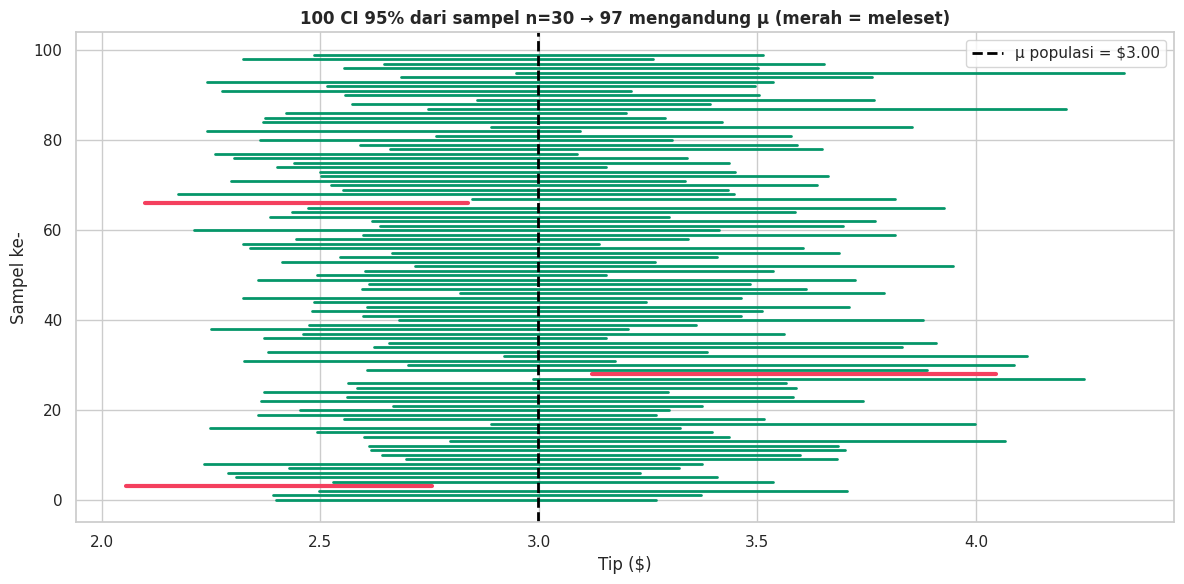

Coverage empiris = 97/100 = 97%  (teori ≈ 95%)
💡 Inilah makna 95%: sifat METODE, bukan peluang satu interval tertentu.


In [ ]:
mu_pop = df['tip'].mean()
n_sim, n_sample = 100, 30
cis, hits = [], 0
for _ in range(n_sim):
    smp = df['tip'].sample(n_sample, replace=False)
    lo, hi = stats.t.interval(0.95, df=n_sample-1, loc=smp.mean(), scale=smp.std(ddof=1)/np.sqrt(n_sample))
    covered = lo <= mu_pop <= hi
    hits += covered
    cis.append((lo, hi, covered))

fig, ax = plt.subplots(figsize=(12, 6))
for i, (lo, hi, ok) in enumerate(cis):
    ax.plot([lo, hi], [i, i], color='#059669' if ok else '#F43F5E', linewidth=2 if ok else 3)
ax.axvline(mu_pop, color='black', linestyle='--', linewidth=2, label=f'μ populasi = ${mu_pop:.2f}')
ax.set_xlabel('Tip ($)'); ax.set_ylabel('Sampel ke-')
ax.set_title(f'100 CI 95% dari sampel n=30 → {hits} mengandung μ (merah = meleset)', fontweight='bold')
ax.legend(); plt.tight_layout(); plt.show()

print(f"Coverage empiris = {hits}/{n_sim} = {hits}%  (teori ≈ 95%)")
print("💡 Inilah makna 95%: sifat METODE, bukan peluang satu interval tertentu.")


---

# 🧮 D. t-test

**Tujuan Pembelajaran 2 & 3** — Kerangka 5 langkah.

## D.1 One-sample t-test: Apakah rata-rata tip = standar industri 15%?

- **H₀**: μ_tip_pct = 15%
- **H₁**: μ_tip_pct ≠ 15%
- **α** = 0.05


In [ ]:
t_stat, p_val = stats.ttest_1samp(df['tip_pct'], popmean=15)
print("=== ONE-SAMPLE T-TEST: tip_pct vs 15% ===")
print(f"  Mean tip_pct = {df['tip_pct'].mean():.2f}%")
print(f"  t = {t_stat:.3f},  p = {p_val:.4f}")
print(f"  Keputusan: {'TOLAK H₀' if p_val < ALPHA else 'GAGAL TOLAK H₀'}")
if p_val < ALPHA:
    print("  → Rata-rata tip% berbeda signifikan dari 15%.")
else:
    print("  → Tidak cukup bukti bahwa rata-rata tip% berbeda dari 15%.")


=== ONE-SAMPLE T-TEST: tip_pct vs 15% ===
  Mean tip_pct = 16.08%
  t = 2.763,  p = 0.0062
  Keputusan: TOLAK H₀
  → Rata-rata tip% berbeda signifikan dari 15%.


## D.2 Two-sample t-test: Apakah tip pria ≠ tip wanita?

- **H₀**: μ_pria = μ_wanita
- **H₁**: μ_pria ≠ μ_wanita

**Langkah 3 — cek asumsi**: normalitas (Shapiro) dan kesamaan varians (Levene). Jika varians berbeda, pakai **Welch's t-test** (`equal_var=False`).


In [ ]:
male, female = df.loc[df.sex == 'Male', 'tip'], df.loc[df.sex == 'Female', 'tip']

print("=== CEK ASUMSI ===")
for name, g in [('Male', male), ('Female', female)]:
    w, p = stats.shapiro(g)
    print(f"  Shapiro {name:<6}: W={w:.3f}, p={p:.4f} → {'normal' if p > ALPHA else 'TIDAK normal'}")
lev_stat, lev_p = stats.levene(male, female)
print(f"  Levene         : p={lev_p:.4f} → varians {'sama' if lev_p > ALPHA else 'BERBEDA'}")
print("  💡 n > 30 per grup → CLT membuat t-test tetap robust meski data tidak normal.")

t_stat, p_val = stats.ttest_ind(male, female, equal_var=False)
pooled_sd = np.sqrt(((len(male)-1)*male.var() + (len(female)-1)*female.var()) / (len(male)+len(female)-2))
cohens_d = (male.mean() - female.mean()) / pooled_sd

print("\n=== WELCH T-TEST: tip Male vs Female ===")
print(f"  Mean Male   = ${male.mean():.3f} (n={len(male)})")
print(f"  Mean Female = ${female.mean():.3f} (n={len(female)})")
print(f"  Selisih     = ${male.mean()-female.mean():.3f}")
print(f"  t = {t_stat:.3f},  p = {p_val:.4f}")
print(f"  Cohen's d   = {cohens_d:.3f}  (|d|<0.2 sangat kecil, 0.5 sedang, 0.8 besar)")
print(f"  Keputusan   : {'TOLAK H₀' if p_val < ALPHA else 'GAGAL TOLAK H₀'}")
print("\n💡 Grafik tampak beda, tapi bukti statistik belum cukup. Efeknya pun kecil.")


=== CEK ASUMSI ===
  Shapiro Male  : W=0.876, p=0.0000 → TIDAK normal
  Shapiro Female: W=0.957, p=0.0054 → TIDAK normal
  Levene         : p=0.1595 → varians sama
  💡 n > 30 per grup → CLT membuat t-test tetap robust meski data tidak normal.

=== WELCH T-TEST: tip Male vs Female ===
  Mean Male   = $3.090 (n=157)
  Mean Female = $2.833 (n=87)
  Selisih     = $0.256
  t = 1.490,  p = 0.1378
  Cohen's d   = 0.185  (|d|<0.2 sangat kecil, 0.5 sedang, 0.8 besar)
  Keputusan   : GAGAL TOLAK H₀

💡 Grafik tampak beda, tapi bukti statistik belum cukup. Efeknya pun kecil.


---

# 📊 E. Chi-Square Test of Independence

Untuk dua variabel **kategorik**. Syarat: frekuensi harapan (expected) tiap sel ≥ 5.

## E.1 Smoker × Time
- **H₀**: status merokok independen dari waktu makan
- **H₁**: ada hubungan


In [ ]:
def chi_square_report(var1, var2):
    ct = pd.crosstab(df[var1], df[var2])
    chi2, p, dof, expected = stats.chi2_contingency(ct)
    n = ct.values.sum()
    cramers_v = np.sqrt(chi2 / (n * (min(ct.shape) - 1)))
    print(f"=== CHI-SQUARE: {var1} × {var2} ===")
    print("Observed:"); print(ct)
    print(f"\nExpected min = {expected.min():.1f}  ({'OK ≥5' if expected.min() >= 5 else 'PERINGATAN <5'})")
    print(f"χ² = {chi2:.3f}, dof = {dof}, p = {p:.4g}")
    print(f"Cramér's V = {cramers_v:.3f}  (0.1 lemah, 0.3 sedang, 0.5 kuat)")
    print(f"Keputusan: {'TOLAK H₀ — ada hubungan' if p < ALPHA else 'GAGAL TOLAK H₀ — tidak ada bukti hubungan'}\n")
    return p

p_smoker_time = chi_square_report('smoker', 'time')


=== CHI-SQUARE: smoker × time ===
Observed:
time    Dinner  Lunch
smoker               
No         106     45
Yes         70     23

Expected min = 25.9  (OK ≥5)
χ² = 0.505, dof = 1, p = 0.4771
Cramér's V = 0.046  (0.1 lemah, 0.3 sedang, 0.5 kuat)
Keputusan: GAGAL TOLAK H₀ — tidak ada bukti hubungan



## E.2 Day × Time
- **H₀**: hari independen dari waktu makan


In [ ]:
p_day_time = chi_square_report('day', 'time')
print("💡 Hampir semua transaksi Thur = Lunch, Sat/Sun = Dinner → hubungan SANGAT kuat.")
print("   Catatan: ada sel expected < 5 — pada laporan nyata, gabungkan kategori atau pakai Fisher's exact.")


=== CHI-SQUARE: day × time ===
Observed:
time  Dinner  Lunch
day                
Fri       12      7
Sat       87      0
Sun       76      0
Thur       1     61

Expected min = 5.3  (OK ≥5)
χ² = 217.113, dof = 3, p = 8.45e-47
Cramér's V = 0.943  (0.1 lemah, 0.3 sedang, 0.5 kuat)
Keputusan: TOLAK H₀ — ada hubungan

💡 Hampir semua transaksi Thur = Lunch, Sat/Sun = Dinner → hubungan SANGAT kuat.
   Catatan: ada sel expected < 5 — pada laporan nyata, gabungkan kategori atau pakai Fisher's exact.


---

# 📈 F. One-way ANOVA + Post-hoc Tukey

Membandingkan mean **≥3 grup** sekaligus. Mengapa tidak t-test berulang? 6 pasang t-test → risiko Error Tipe I membengkak (ingat Bonferroni di M5).

- **H₀**: μ_Thur = μ_Fri = μ_Sat = μ_Sun
- **H₁**: minimal satu hari berbeda


In [ ]:
order = ['Thur', 'Fri', 'Sat', 'Sun']
groups = [df.loc[df.day == d, 'total_bill'] for d in order]

print("Mean total_bill per hari:")
print(df.groupby('day')['total_bill'].agg(['mean', 'std', 'count']).loc[order].round(2))

lev_p = stats.levene(*groups).pvalue
f_stat, p_val = stats.f_oneway(*groups)
grand = df['total_bill'].mean()
ss_between = sum(len(g) * (g.mean() - grand)**2 for g in groups)
ss_total = ((df['total_bill'] - grand)**2).sum()
eta_sq = ss_between / ss_total

print(f"\nLevene p = {lev_p:.4f}")
print(f"=== ONE-WAY ANOVA: total_bill ~ day ===")
print(f"  F = {f_stat:.3f},  p = {p_val:.4f}")
print(f"  η² (eta squared) = {eta_sq:.3f}  → {eta_sq*100:.1f}% variasi bill dijelaskan oleh hari")
print(f"  Keputusan: {'TOLAK H₀ — minimal satu hari berbeda' if p_val < ALPHA else 'GAGAL TOLAK H₀'}")


Mean total_bill per hari:
       mean   std  count
day                     
Thur  17.68  7.89     62
Fri   17.15  8.30     19
Sat   20.44  9.48     87
Sun   21.41  8.83     76

Levene p = 0.5741
=== ONE-WAY ANOVA: total_bill ~ day ===
  F = 2.767,  p = 0.0425
  η² (eta squared) = 0.033  → 3.3% variasi bill dijelaskan oleh hari
  Keputusan: TOLAK H₀ — minimal satu hari berbeda


In [ ]:
# ANOVA hanya bilang "ada yang beda" — Tukey HSD memberi tahu PASANGAN mana
tukey = pairwise_tukeyhsd(endog=df['total_bill'], groups=df['day'], alpha=ALPHA)
print(tukey.summary())
print("\n💡 Kolom 'reject' = True menandai pasangan yang berbeda signifikan.")
print("   Perhatikan: ANOVA signifikan, tapi bisa saja tidak ada pasangan yang lolos Tukey —")
print("   ini terjadi saat efek tersebar tipis di beberapa pasangan (p ANOVA dekat 0.05).")


Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower   upper  reject
----------------------------------------------------
   Fri    Sat   3.2898 0.4541 -2.4799  9.0595  False
   Fri    Sun   4.2584 0.2371 -1.5856 10.1025  False
   Fri   Thur   0.5312 0.9957 -5.4434  6.5057  False
   Sat    Sun   0.9686 0.8968 -2.6088   4.546  False
   Sat   Thur  -2.7586 0.2374 -6.5455  1.0282  False
   Sun   Thur  -3.7273 0.0668 -7.6264  0.1719  False
----------------------------------------------------

💡 Kolom 'reject' = True menandai pasangan yang berbeda signifikan.
   Perhatikan: ANOVA signifikan, tapi bisa saja tidak ada pasangan yang lolos Tukey —
   ini terjadi saat efek tersebar tipis di beberapa pasangan (p ANOVA dekat 0.05).


---

# 🔗 G. Korelasi & Tabel Ringkasan

## G.1 Uji Korelasi Pearson: total_bill vs tip
- **H₀**: ρ = 0 (tidak ada korelasi linier)


Pearson  r = 0.676,  p = 6.69e-34
Spearman ρ = 0.679,  p = 2.50e-34


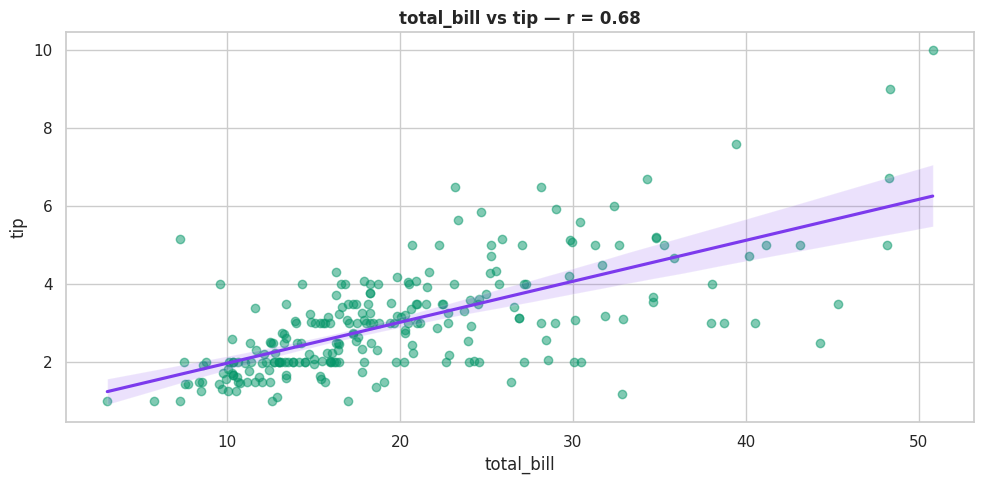

💡 Korelasi positif kuat & signifikan → fondasi regresi linier di Modul 11.


In [ ]:
r, p_r = stats.pearsonr(df['total_bill'], df['tip'])
rho, p_rho = stats.spearmanr(df['total_bill'], df['tip'])
print(f"Pearson  r = {r:.3f},  p = {p_r:.2e}")
print(f"Spearman ρ = {rho:.3f},  p = {p_rho:.2e}")

sns.regplot(x='total_bill', y='tip', data=df, scatter_kws={'alpha':0.5, 'color':'#059669'}, line_kws={'color':'#7C3AED'})
plt.title(f'total_bill vs tip — r = {r:.2f}', fontweight='bold'); plt.tight_layout(); plt.show()
print("💡 Korelasi positif kuat & signifikan → fondasi regresi linier di Modul 11.")


## G.2 Ringkasan Semua Uji


In [ ]:
summary = pd.DataFrame([
    ['tip_pct = 15%?',           'One-sample t',  stats.ttest_1samp(df.tip_pct, 15).pvalue],
    ['tip Male ≠ Female?',       'Welch t-test',  stats.ttest_ind(male, female, equal_var=False).pvalue],
    ['smoker ⟂ time?',           'Chi-square',    p_smoker_time],
    ['day ⟂ time?',              'Chi-square',    p_day_time],
    ['total_bill beda per hari?','One-way ANOVA', stats.f_oneway(*groups).pvalue],
    ['total_bill ~ tip korelasi?','Pearson r',    p_r],
], columns=['Hipotesis', 'Uji', 'p-value'])
summary['Keputusan (α=0.05)'] = np.where(summary['p-value'] < ALPHA, 'Tolak H₀', 'Gagal tolak H₀')
summary['p-value'] = summary['p-value'].apply(lambda v: f"{v:.2e}" if v < 0.001 else f"{v:.4f}")
summary


,Hipotesis,Uji,p-value,Keputusan (α=0.05)
0,tip_pct = 15%?,One-sample t,0.0062,Tolak H₀
1,tip Male ≠ Female?,Welch t-test,0.1378,Gagal tolak H₀
2,smoker ⟂ time?,Chi-square,0.4771,Gagal tolak H₀
3,day ⟂ time?,Chi-square,8.45e-47,Tolak H₀
4,total_bill beda per hari?,One-way ANOVA,0.0425,Tolak H₀
5,total_bill ~ tip korelasi?,Pearson r,6.69e-34,Tolak H₀


## ✅ Rangkuman Hasil Praktikum 10 (dari output notebook Anda)

| Bagian | Hasil kunci |
|---|---|
| **A-B Data** | 244 transaksi × 8 kolom (7 asli + `tip_pct`). Rata-rata tip $3,00; tip_pct 16,08%; total_bill $19,79. Male 157, Female 87. Dinner 176, Lunch 68. |
| **C.1 CI 95% tip** | x̄ = $2,998; s = $1,384; SE = 0,0886; t kritis = 1,9698; margin = 0,1745 → **CI 95% = [$2,824; $3,173]** (scipy sama ✅) |
| **C.1 Level CI** | 80% lebar 0,228 · 90% lebar 0,293 · 95% lebar 0,349 · 99% lebar 0,460. Makin tinggi kepercayaan, makin lebar. |
| **C.2 Simulasi** | **97/100** interval mengandung μ (teori ≈ 95%) |
| **D.1 One-sample t** | tip_pct 16,08% vs 15%: t = 2,763; p = 0,0062 → **Tolak H₀** |
| **D.2 Welch t** | Male $3,090 vs Female $2,833, selisih $0,256. t = 1,490; **p = 0,1378**; Cohen's d = 0,185 → **Gagal tolak H₀**. Shapiro: tidak normal (Male p = 0,0000; Female p = 0,0054). Levene p = 0,1595 (varians sama). n > 30 per grup, jadi t-test tetap robust. |
| **E.1 Smoker × Time** | χ² = 0,505; dof = 1; p = 0,4771; Cramér's V = 0,046; expected min 25,9 → **Gagal tolak H₀** |
| **E.2 Day × Time** | χ² = 217,113; dof = 3; p = 8,45e-47; Cramér's V = 0,943; expected min 5,3 → **Tolak H₀** (hubungan sangat kuat) |
| **F ANOVA** | Mean bill: Thur 17,68; Fri 17,15; Sat 20,44; Sun 21,41. Levene p = 0,5741. **F = 2,767; p = 0,0425; η² = 0,033** → **Tolak H₀** (efek lemah, 3,3%) |
| **F Tukey HSD** | Semua `reject = False`. Terdekat Sun vs Thur: selisih −3,73; p-adj = **0,0668** |
| **G Korelasi** | Pearson r = 0,676 (p = 6,69e-34); Spearman ρ = 0,679 (p = 2,50e-34) → korelasi positif kuat |

**Kesimpulan besar:** dari 6 uji, 4 menolak H₀ dan 2 gagal menolak H₀ (tip pria vs wanita, smoker × time). Hasil campuran inilah latihan membaca p-value dengan jujur. Catatan: komentar di notebook menyebut ada sel expected < 5 pada Day × Time, padahal output menunjukkan expected minimum 5,3 (syarat ≥ 5 masih terpenuhi, tetapi tipis).


---

# 📝 H. Template Milestone 2 + Refleksi

## H.1 Template Uji Hipotesis untuk Dataset Anda

Copy cell di bawah ke **notebook Milestone 1 Anda** (dataset Kaggle yang sama), lalu isi 2-3 hipotesis yang berasal dari insight EDA.


In [ ]:
# =========================================================
# TEMPLATE MILESTONE 2 — ganti dengan dataset & kolom Anda
# =========================================================
# df_my = pd.read_csv("<URL dataset Milestone 1 Anda>")

# ---------- CI 95% untuk metrik utama ----------
# col = '<kolom_numerik_utama>'
# x = df_my[col].dropna()
# print(stats.t.interval(0.95, df=len(x)-1, loc=x.mean(), scale=x.std(ddof=1)/np.sqrt(len(x))))

# ---------- HIPOTESIS 1 ----------
# Insight EDA   : "<tulis insight dari Milestone 1>"
# H0            : ...
# H1            : ...
# Uji dipilih   : <t-test / chi-square / ANOVA / pearson> karena <tipe data & jumlah grup>
# Cek asumsi    : stats.shapiro(...), stats.levene(...), expected >= 5
# Hasil         : stat, p = stats.<uji>(...)
# Effect size   : Cohen's d / Cramér's V / η² / r
# Kesimpulan    : statistik + bahasa bisnis

# ---------- HIPOTESIS 2 & 3 ----------
# (ulangi struktur di atas)

print("💡 Gunakan fungsi & pola dari Bagian C-G notebook ini sebagai referensi.")
print("   Submit sebelum pertemuan Modul 11 (link GitHub via LMS).")


💡 Gunakan fungsi & pola dari Bagian C-G notebook ini sebagai referensi.
   Submit sebelum pertemuan Modul 11 (link GitHub via LMS).


### Contoh pengisian template (dataset *Students Performance in Exams*)

Cell di bawah adalah contoh template yang sudah diisi. Jalankan setelah mengunggah `StudentsPerformance.csv`; ganti dengan dataset Milestone 1 Anda.

In [ ]:
# CONTOH PENGISIAN TEMPLATE MILESTONE 2 — Students Performance in Exams
# (ganti dengan dataset Milestone 1 Anda; butuh StudentsPerformance.csv dari Kaggle)
df_my = pd.read_csv('StudentsPerformance.csv')
df_my.columns = [c.replace(' ', '_').replace('/', '_') for c in df_my.columns]

# ---------- CI 95% untuk metrik utama ----------
x = df_my['math_score'].dropna()
ci = stats.t.interval(0.95, df=len(x)-1, loc=x.mean(), scale=x.std(ddof=1)/np.sqrt(len(x)))
print(f"CI 95% math_score: [{ci[0]:.2f}, {ci[1]:.2f}]")

# ---------- HIPOTESIS 1: kursus persiapan vs nilai matematika ----------
# H0: mu_completed = mu_none | H1: mu_completed != mu_none | alpha = 0.05
a = df_my.loc[df_my.test_preparation_course == 'completed', 'math_score']
b = df_my.loc[df_my.test_preparation_course == 'none', 'math_score']
print("Levene p =", round(stats.levene(a, b).pvalue, 4))
t_stat, p = stats.ttest_ind(a, b, equal_var=False)
sp = np.sqrt(((len(a)-1)*a.var() + (len(b)-1)*b.var()) / (len(a)+len(b)-2))
print(f"H1 -> t = {t_stat:.3f}, p = {p:.4g}, Cohen's d = {(a.mean()-b.mean())/sp:.3f}")

# ---------- HIPOTESIS 2: pendidikan orang tua vs nilai matematika ----------
# H0: semua rata-rata sama | H1: minimal satu berbeda
grp = [g['math_score'] for _, g in df_my.groupby('parental_level_of_education')]
f_stat, p2 = stats.f_oneway(*grp)
print(f"H2 -> F = {f_stat:.3f}, p = {p2:.4g}")
print(pairwise_tukeyhsd(df_my['math_score'], df_my['parental_level_of_education']).summary())

# ---------- HIPOTESIS 3 (opsional): reading vs writing ----------
r, p3 = stats.pearsonr(df_my['reading_score'], df_my['writing_score'])
print(f"H3 -> r = {r:.3f}, p = {p3:.2e}")


## H.2 Pertanyaan Refleksi (sudah dijawab)

### ✏️ Jawaban Anda:

**1. CI dan angka 95%.** Tidak, itu **bukan** berarti perhitungannya salah. "95%" adalah sifat **metode**: kalau sampling diulang banyak kali dan CI dihitung tiap kali, sekitar 95% interval akan mengandung μ dan sekitar 5% meleset hanya karena kebetulan sampling. Pada simulasi Anda, **97 dari 100** interval mengandung μ (3 garis merah meleset). Angka itu wajar dan dekat 95%; hasil sebenarnya akan bergeser sedikit tiap kali dijalankan (secara acak bisa sekitar 92 sampai 98). Itu juga menjelaskan interpretasi yang benar: bukan "ada peluang 95% μ berada di interval ini" (μ itu konstanta; interval yang sudah jadi mengandung μ atau tidak).

**2. p-value dan effect size.** Dengan selisih yang sama ($0,256) dan 100.000 transaksi (sekitar 50.000 per grup), statistik uji menjadi sangat besar (z ≈ 29) dan **p-value turun drastis** (orde 10⁻¹⁸⁹), sehingga hasilnya "sangat signifikan". Tetapi **ukuran efeknya tidak berubah**: Cohen's d tetap ≈ 0,185 (kecil), dan selisih $0,26 hanya sekitar 8,5% dari tip rata-rata $3,00. Jadi signifikan secara statistik belum berarti penting secara bisnis (mirip pelajaran p = 10⁻¹⁹⁴ di Modul 5). Selalu laporkan **effect size** dan CI selisih, bukan hanya p-value.

**3. Error Tipe I vs II pada fraud e-wallet.** H₀ = transaksi normal. **Tipe I** = transaksi normal dianggap fraud (diblokir, pelanggan kesal). **Tipe II** = fraud lolos tidak terdeteksi (uang hilang dan reputasi rusak). Umumnya **Tipe II lebih mahal**, jadi detektor dibuat lebih sensitif: pilih α **lebih besar** (misal 0,10) supaya β (kemungkinan fraud lolos) turun. Konsekuensinya lebih banyak alarm palsu, yang bisa ditangani dengan verifikasi tambahan seperti OTP. (Menurunkan α menaikkan β: itu trade-off.)

**4. ANOVA vs banyak t-test.** Membandingkan 4 hari butuh 6 pasangan t-test. Tiap uji punya risiko Error Tipe I 5%, sehingga peluang minimal satu temuan palsu menumpuk: 1 − 0,95⁶ ≈ **26%** (perkiraan kasar). ANOVA menguji semua hari dengan **satu uji global** pada α = 0,05. Lalu Tukey HSD membandingkan pasangan sambil mengendalikan kesalahan gabungan (FWER = 0,05). Ini konsep yang sama dengan **Bonferroni** di Modul 5: bagi α dengan jumlah uji (0,05/6 ≈ 0,0083). Hasil Anda menunjukkan manfaatnya: ANOVA signifikan (p = 0,0425), tetapi setelah Tukey **tidak ada** pasangan yang signifikan (terdekat Sun vs Thur, p-adj = 0,0668).

**5. Milestone 2 (contoh memakai dataset *Students Performance in Exams* seperti contoh Milestone 1; ganti dengan dataset Anda).**

- **Hipotesis 1.** Insight EDA: siswa yang ikut kursus persiapan tampak punya nilai matematika lebih tinggi. H₀: μ_kursus = μ_tanpa kursus. H₁: μ_kursus ≠ μ_tanpa kursus. **Uji:** Welch two-sample t-test, karena satu variabel numerik (math score) dan dua grup independen. Asumsi: Shapiro-Wilk (normalitas), Levene (varians), n > 30 per grup. Effect size: Cohen's d.
- **Hipotesis 2.** Insight EDA: nilai berbeda antar tingkat pendidikan orang tua. H₀: rata-rata nilai sama di semua tingkat pendidikan. H₁: minimal satu tingkat berbeda. **Uji:** One-way ANOVA (numerik × 6 grup), dilanjutkan Tukey HSD. Effect size: η².
- **Hipotesis 3 (opsional).** H₀: ρ = 0 antara reading dan writing score. H₁: ρ ≠ 0. **Uji:** Pearson r (dua variabel numerik).


## H.3 Checklist Submit

### Praktikum (notebook ini)
- [ ] Semua cell berjalan tanpa error
- [ ] CI 95% manual = scipy
- [ ] Plot simulasi 100 CI muncul (coverage ≈ 95%)
- [ ] t-test, chi-square, ANOVA + Tukey, Pearson selesai
- [ ] Tabel ringkasan semua uji muncul
- [ ] 5 pertanyaan refleksi dijawab

### Milestone 2 (notebook projek Anda)
- [ ] Minimal 1 CI 95% untuk metrik utama
- [ ] 2-3 hipotesis berasal dari insight Milestone 1
- [ ] Tiap hipotesis: H₀, H₁, α, alasan uji, cek asumsi
- [ ] Statistik uji + p-value + effect size
- [ ] Kesimpulan statistik + bahasa bisnis
- [ ] README diperbarui, commit: `"Milestone 2: hypothesis testing"`
- [ ] Link GitHub dikumpulkan via LMS **sebelum Modul 11**

---

## 🎓 Selamat! Anda Berhasil...

✅ Menghitung dan menafsirkan CI 95% dengan benar
✅ Membuktikan makna "95%" lewat simulasi
✅ Menjalankan t-test, chi-square, ANOVA + Tukey, dan uji korelasi
✅ Melaporkan effect size, bukan hanya p-value

## 📚 Bacaan Lanjutan
- **Bruce, P.** (2020). *Practical Statistics for Data Scientists*, Ch. 3 (Statistical Experiments & Significance Testing).
- **Wasserstein & Lazar** (2016). *The ASA Statement on p-Values* — The American Statistician.
- **StatQuest** — "p-values, clearly explained", "t-tests", "ANOVA".

## 🔮 Persiapan Modul 11 — Korelasi & Regresi
- Regresi linier sederhana & berganda, uji signifikansi koefisien
- **Milestone 3 Projek**: model prediktif dari dataset Anda
- **Quiz 3 (Inferensial, bobot 5%)** — jadwal diumumkan via LMS

---

*Notebook by: Prodi Teknik Informatika · Uniska MAB Banjarmasin · Edisi 2026*
